# Libraries

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Model Parameters (from slide specifications)

In [19]:

params = {
    'c_s': 420.0,  # Soil water holding capacity (mm)
    'alpha': 4.0,  # Runoff function shape parameter (alpha >= 0)
    'gamma': 0.5,  # ET function shape parameter (gamma > 0)
    'beta_0': 0.8,  # Maximum ET fraction parameter (beta_0 <= 1)
}

# State Variable: Initial soil moisture (0.9 * c_s)

In [20]:
initial_soil_moisture = 0.9 * params['c_s']  # 378.0 mm

# Driving Data (Rainfall P and Radiation R for n number of days)

In [21]:
days = 1000
np.random.seed(42)
driving_data = pd.DataFrame({
    'day': np.arange(days),
    'rainfall': np.random.gamma(
        shape=2, scale=5, size=days
    ),  # Daily precipitation P_n (mm)
    'radiation': 4.0
    + 1.5 * np.sin(np.arange(days) / days * 2 * np.pi),  # Daily net radiation R_n (mm eq)
})

# Model Components output

In [22]:
print("Model Components:")
print("\nParameters:")
for param, value in params.items():
  print(f"  {param}: {value}")
print(f"\nInitial Soil Moisture: {initial_soil_moisture:.1f} mm")
print("\nDriving Data Summary:")
print(f"  Total Rainfall (P): {driving_data['rainfall'].sum():.1f} mm")
print(
    f"  Average Radiation (R): {driving_data['radiation'].mean():.2f} mm/day"
)

Model Components:

Parameters:
  c_s: 420.0
  alpha: 4.0
  gamma: 0.5
  beta_0: 0.8

Initial Soil Moisture: 378.0 mm

Driving Data Summary:
  Total Rainfall (P): 10299.7 mm
  Average Radiation (R): 4.00 mm/day


# Core Flux & State Functions


In [23]:
def calculate_runoff(soil_moisture, precipitation, c_s, alpha):
  """Calculates runoff Q_n = P_n * (SM_n / c_s)^alpha"""
  runoff_fraction = (soil_moisture / c_s) ** alpha
  return precipitation * runoff_fraction

def calculate_evapotranspiration(soil_moisture, radiation, c_s, gamma, beta_0):
  """Calculates evapotranspiration ET_n = R_n * beta_0 * (SM_n / c_s)^gamma"""
  et_fraction = beta_0 * ((soil_moisture / c_s) ** gamma)
  return radiation * et_fraction

def update_soil_moisture(
    current_sm, precipitation, radiation, params, delta_t=1.0
):
  """Updates soil moisture state using the forward water balance equation:

  SM_{n+1} = SM_n + (P_n - Q_n - ET_n) * delta_t
  """
  Q = calculate_runoff(
      current_sm, precipitation, params['c_s'], params['alpha']
  )
  ET = calculate_evapotranspiration(
      current_sm,
      radiation,
      params['c_s'],
      params['gamma'],
      params['beta_0'],
  )
   # Update equation
  next_sm = current_sm + (precipitation - Q - ET) * delta_t
  
  # Ensure physically realistic bounds [0, c_s]
  next_sm = max(0.0, min(params['c_s'], next_sm))
  
  return next_sm, Q, ET

# Simulation Loop

In [24]:
sm_history = []
q_history = []
et_history = []

current_sm = initial_soil_moisture

for _, row in driving_data.iterrows():
  sm_history.append(current_sm)
  current_sm, Q, ET = update_soil_moisture(
      current_sm, row['rainfall'], row['radiation'], params
  )
  q_history.append(Q)
  et_history.append(ET)

driving_data['soil_moisture'] = sm_history
driving_data['runoff'] = q_history
driving_data['ET'] = et_history

# Visualization

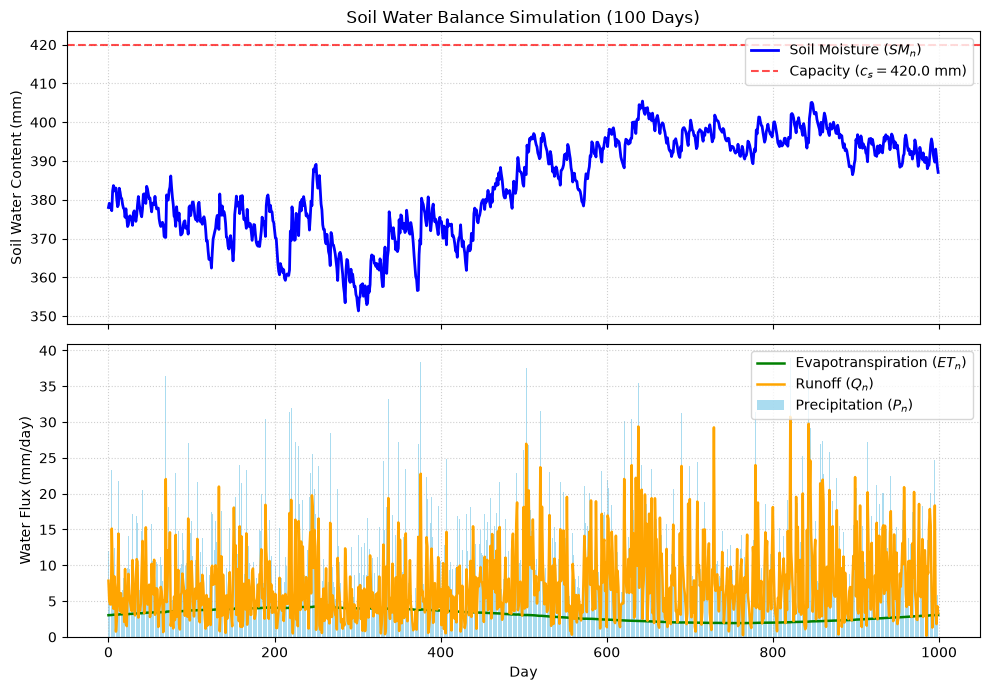

In [25]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Soil Moisture State
ax1.plot(
    driving_data['day'],
    driving_data['soil_moisture'],
    color='blue',
    linewidth=2,
    label='Soil Moisture ($SM_n$)',
)
ax1.axhline(
    y=params['c_s'],
    color='red',
    linestyle='--',
    alpha=0.7,
    label=f"Capacity ($c_s = {params['c_s']}$ mm)",
)
ax1.set_ylabel('Soil Water Content (mm)')
ax1.set_title('Soil Water Balance Simulation (100 Days)')
ax1.legend(loc='upper right')
ax1.grid(True, linestyle=':', alpha=0.6)

# Daily Water Fluxes (P, Q, ET)
ax2.bar(
    driving_data['day'],
    driving_data['rainfall'],
    color='skyblue',
    alpha=0.7,
    label='Precipitation ($P_n$)',
)
ax2.plot(
    driving_data['day'],
    driving_data['ET'],
    color='green',
    linewidth=1.8,
    label='Evapotranspiration ($ET_n$)',
)
ax2.plot(
    driving_data['day'],
    driving_data['runoff'],
    color='orange',
    linewidth=1.8,
    label='Runoff ($Q_n$)',
)
ax2.set_xlabel('Day')
ax2.set_ylabel('Water Flux (mm/day)')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()